In [3]:
# Получение тестовых данных для проекта по анализу медицинских изображений (OCT).

import os
import re
import pandas as pd
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
import kagglehub

# ==================== Настройки ====================
DATA_DIR = Path("data")
METADATA_PATH = DATA_DIR / "metadata.csv"
SPLITS_SUMMARY_PATH = DATA_DIR / "splits_summary.csv"
RANDOM_STATE = 42

DATA_DIR.mkdir(exist_ok=True)

# ==================== Загрузка или создание metadata ====================
if METADATA_PATH.exists():
    print(f"Найден готовый {METADATA_PATH}, загружаю...")
    df = pd.read_csv(METADATA_PATH)
    print(f"Загружено записей: {len(df)}")
    print(f"Уникальных пациентов: {df['patient_id'].nunique()}")

else:
    print("metadata.csv не найден. Запускаю полный пайплайн...")

    # 1. Скачивание / получение из кэша
    print("Получаю датасет через kagglehub...")
    dataset_path = Path(kagglehub.dataset_download("paultimothymooney/kermany2018"))
    print(f"Путь к датасету: {dataset_path}")

    # Ищем папку с train/test/val
    oct_dir = None
    for root, dirs, files in os.walk(dataset_path):
        if any(d in dirs for d in ["train", "test", "val"]):
            oct_dir = Path(root)
            break

    if oct_dir is None:
        raise FileNotFoundError("Не удалось найти папку с train/test/val внутри датасета")

    print(f"Рабочая папка с изображениями: {oct_dir}")

    # 2. Сбор метаданных
    records = []
    pattern = re.compile(r"([A-Z]+)-(\d+)-(\d+)\.jpeg", re.IGNORECASE)

    for split in ["train", "test", "val"]:
        split_path = oct_dir / split
        if not split_path.exists():
            continue
        for class_dir in split_path.iterdir():
            if not class_dir.is_dir():
                continue
            label = class_dir.name.upper()
            for img_path in class_dir.glob("*.jpeg"):
                match = pattern.search(img_path.name)
                if match:
                    patient_id = match.group(2)
                    records.append({
                        "path": str(img_path),
                        "label": label,
                        "patient_id": patient_id,
                        "original_split": split,
                        "filename": img_path.name
                    })

    df = pd.DataFrame(records)
    print(f"Всего изображений собрано: {len(df)}")
    print(f"Уникальных пациентов: {df['patient_id'].nunique()}")

    # 3. Patient-level stratified split (70/15/15)
    patient_df = (
        df.groupby("patient_id")
          .agg(label=("label", lambda x: x.mode()[0]),
               n_images=("path", "count"))
          .reset_index()
    )

    # Сначала отделяем train (70%)
    gss1 = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=RANDOM_STATE)
    train_idx, temp_idx = next(gss1.split(patient_df, groups=patient_df["patient_id"]))

    # Из оставшихся 30% делим пополам на val и test
    temp_df = patient_df.iloc[temp_idx].reset_index(drop=True)
    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=RANDOM_STATE)
    val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df["patient_id"]))

    train_patients = set(patient_df.iloc[train_idx]["patient_id"])
    val_patients   = set(temp_df.iloc[val_idx]["patient_id"])
    test_patients  = set(temp_df.iloc[test_idx]["patient_id"])

    def assign_split(pid):
        if pid in train_patients:
            return "train"
        elif pid in val_patients:
            return "val"
        else:
            return "test"

    df["split"] = df["patient_id"].apply(assign_split)

    # 4. Сохранение
    df.to_csv(METADATA_PATH, index=False)
    splits_summary = (
        df.groupby(["split", "label"])
          .size()
          .reset_index(name="count")
    )
    splits_summary.to_csv(SPLITS_SUMMARY_PATH, index=False)

    print(f"\nСохранено:")
    print(f"- {METADATA_PATH}")
    print(f"- {SPLITS_SUMMARY_PATH}")

# ==================== Полное распределение по классам ====================
print("\n" + "="*60)
print("ПОЛНОЕ РАСПРЕДЕЛЕНИЕ ДАННЫХ")
print("="*60)

print(f"\nВсего изображений: {len(df)}")
print(f"Уникальных пациентов: {df['patient_id'].nunique()}")

print("\n--- Распределение изображений по классам (всего) ---")
class_counts = df["label"].value_counts().sort_index()
class_pct = (class_counts / len(df) * 100).round(2)
class_dist = pd.DataFrame({
    "count": class_counts,
    "percent": class_pct
})
print(class_dist)

print("\n--- Распределение пациентов по классам (по доминирующему классу) ---")
patient_class = df.groupby("patient_id")["label"].agg(lambda x: x.mode()[0])
patient_counts = patient_class.value_counts().sort_index()
patient_pct = (patient_counts / len(patient_class) * 100).round(2)  # <-- исправлено
patient_dist = pd.DataFrame({
    "patients": patient_counts,
    "percent": patient_pct
})
print(patient_dist)

print("\n--- Распределение изображений по сплитам и классам ---")
split_class = df.groupby(["split", "label"]).size().unstack(fill_value=0)
split_class["total"] = split_class.sum(axis=1)
print(split_class)

print("\n--- Процентное распределение по сплитам ---")
print(df["split"].value_counts(normalize=True).mul(100).round(2))

print("\n--- Распределение пациентов по сплитам ---")
patient_split = df.groupby("patient_id")["split"].first().value_counts()
print(patient_split)

# ==================== Удобные переменные ====================
print("\n" + "="*60)
print("Готово к использованию")
print(f"Train: {(df['split'] == 'train').sum()} изображений")
print(f"Val:   {(df['split'] == 'val').sum()} изображений")
print(f"Test:  {(df['split'] == 'test').sum()} изображений")

train_df = df[df["split"] == "train"]
val_df   = df[df["split"] == "val"]
test_df  = df[df["split"] == "test"]

print("\nМожно использовать train_df / val_df / test_df или полный df.")

d:\Learning\Practise\Year project\12-medical-image-analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Найден готовый data\metadata.csv, загружаю...
Загружено записей: 84484
Уникальных пациентов: 4657

ПОЛНОЕ РАСПРЕДЕЛЕНИЕ ДАННЫХ

Всего изображений: 84484
Уникальных пациентов: 4657

--- Распределение изображений по классам (всего) ---
        count  percent
label                 
CNV     37455    44.33
DME     11598    13.73
DRUSEN   8866    10.49
NORMAL  26565    31.44

--- Распределение пациентов по классам (по доминирующему классу) ---
        patients  percent
label                    
CNV          642    13.79
DME          532    11.42
DRUSEN       448     9.62
NORMAL      3035    65.17

--- Распределение изображений по сплитам и классам ---
label    CNV   DME  DRUSEN  NORMAL  total
split                                    
test    7642  1673    1051    3891  14257
train  24205  8127    6067   18669  57068
val     5608  1798    1748    4005  13159

--- Процентное распределение по сплитам ---
split
train    67.55
test     16.88
val      15.58
Name: proportion, dtype: float64

--- Ра

In [4]:
df

,path,label,patient_id,original_split,filename,split
0,C:\Users\Пользователь\.cache\kagglehub\dataset...,CNV,1016042,train,CNV-1016042-1.jpeg,val
1,C:\Users\Пользователь\.cache\kagglehub\dataset...,CNV,1016042,train,CNV-1016042-10.jpeg,val
2,C:\Users\Пользователь\.cache\kagglehub\dataset...,CNV,1016042,train,CNV-1016042-100.jpeg,val
3,C:\Users\Пользователь\.cache\kagglehub\dataset...,CNV,1016042,train,CNV-1016042-101.jpeg,val
4,C:\Users\Пользователь\.cache\kagglehub\dataset...,CNV,1016042,train,CNV-1016042-102.jpeg,val
...,...,...,...,...,...,...
84479,C:\Users\Пользователь\.cache\kagglehub\dataset...,NORMAL,5193994,val,NORMAL-5193994-1.jpeg,val
84480,C:\Users\Пользователь\.cache\kagglehub\dataset...,NORMAL,5246808,val,NORMAL-5246808-1.jpeg,train
84481,C:\Users\Пользователь\.cache\kagglehub\dataset...,NORMAL,5246808,val,NORMAL-5246808-2.jpeg,train
84482,C:\Users\Пользователь\.cache\kagglehub\dataset...,NORMAL,5324912,val,NORMAL-5324912-1.jpeg,train


In [5]:
# ========== Данные ==========
train_df = df[df["split"] == "train"]
test_df  = df[df["split"] == "test"]
val_df   = df[df["split"] == "val"]

In [6]:
# загрузка изображений в массивы numpy с кешированием

import numpy as np
from PIL import Image
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm
from pathlib import Path

# ========== Настройки ==========
SIZE = 32   # размер картинки

CACHE_DIR = Path("data/cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def load_images_cached(df_subset, size=32, cache_name="train"):
    """
    df_subset — кусок df (train/val/test)
    cache_name — имя файла кеша, например "train"
    """
    cache_path = CACHE_DIR / f"{cache_name}_{size}.npy"
    
    if cache_path.exists():
        print(f"Загружаю из кеша: {cache_path}")
        return np.load(cache_path)
    
    print(f"Кеша нет, обрабатываю {len(df_subset)} изображений...")
    X = []
    for p in tqdm(df_subset["path"]):
        img = Image.open(p).convert("L").resize((size, size))
        X.append(np.array(img).flatten() / 255.0)
    
    X = np.array(X, dtype=np.float32)
    np.save(cache_path, X)
    print(f"Сохранено в {cache_path}")
    return X

print("Загружаю изображения...")
X_train = load_images_cached(train_df, cache_name="train")
X_val   = load_images_cached(val_df, cache_name="val")
X_test  = load_images_cached(test_df, cache_name="test")

Загружаю изображения...
Загружаю из кеша: data\cache\train_32.npy
Загружаю из кеша: data\cache\val_32.npy
Загружаю из кеша: data\cache\test_32.npy


In [7]:
# ставим классам числа в соответствии с их порядком
le = LabelEncoder()
y_train = le.fit_transform(train_df.label)
y_val   = le.transform(val_df.label)
y_test  = le.transform(test_df.label)

print("Классы:", le.classes_)

Классы: ['CNV' 'DME' 'DRUSEN' 'NORMAL']


In [8]:
# обучение логистической регрессии

from sklearn.linear_model import LogisticRegression

# ========== Обучение ==========
print("Обучаю логрег...")
model = LogisticRegression(max_iter=1000, class_weight="balanced", n_jobs=-1, random_state=42)
model.fit(X_train, y_train)

Обучаю логрег...


d:\Learning\Practise\Year project\12-medical-image-analysis\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"n_jobs n_jobs: int, default=NoneDoes not have any effect... deprecated:: 1.8 `n_jobs` is deprecated in version 1.8 and will be removed in 1.10.",-1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_


  VAL
Accuracy:     0.4537
Macro-F1:     0.4020
ROC-AUC:      0.6835

Recall по классам:
  CNV     : 0.4806
  DME     : 0.2981
  DRUSEN  : 0.3158
  NORMAL  : 0.5461

Classification Report:
              precision    recall  f1-score   support

         CNV       0.69      0.48      0.57      5608
         DME       0.21      0.30      0.25      1798
      DRUSEN       0.20      0.32      0.24      1748
      NORMAL       0.55      0.55      0.55      4005

    accuracy                           0.45     13159
   macro avg       0.41      0.41      0.40     13159
weighted avg       0.52      0.45      0.48     13159

Confusion Matrix:
         CNV   DME  DRUSEN  NORMAL
CNV     2695  1142    1004     767
DME      457   536     350     455
DRUSEN   353   272     552     571
NORMAL   381   545     892    2187
Сохранено: results\cm_val_logreg.csv


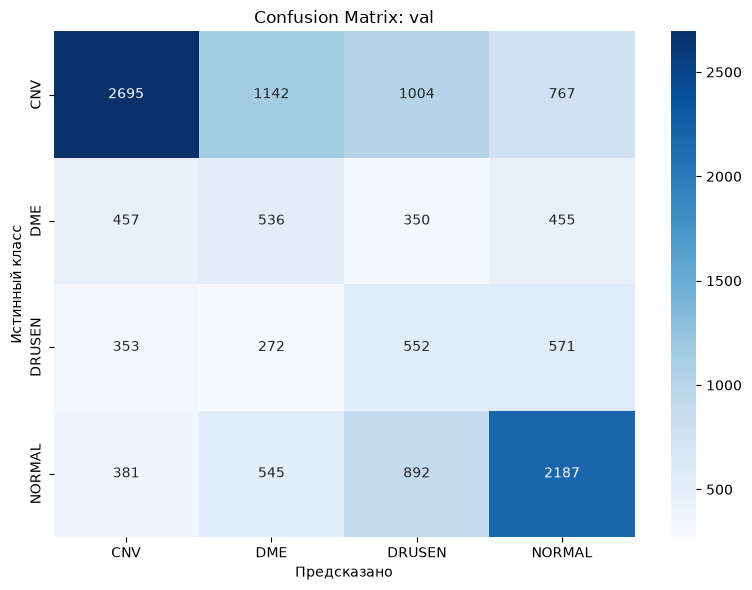

Сохранено: results\cm_val_logreg.png

  TEST
Accuracy:     0.4964
Macro-F1:     0.4014
ROC-AUC:      0.7142

Recall по классам:
  CNV     : 0.5406
  DME     : 0.3060
  DRUSEN  : 0.3073
  NORMAL  : 0.5425

Classification Report:
              precision    recall  f1-score   support

         CNV       0.81      0.54      0.65      7642
         DME       0.17      0.31      0.22      1673
      DRUSEN       0.13      0.31      0.18      1051
      NORMAL       0.56      0.54      0.55      3891

    accuracy                           0.50     14257
   macro avg       0.42      0.42      0.40     14257
weighted avg       0.62      0.50      0.54     14257

Confusion Matrix:
         CNV   DME  DRUSEN  NORMAL
CNV     4131  1720     935     856
DME      340   512     326     495
DRUSEN   220   173     323     335
NORMAL   378   530     872    2111
Сохранено: results\cm_test_logreg.csv


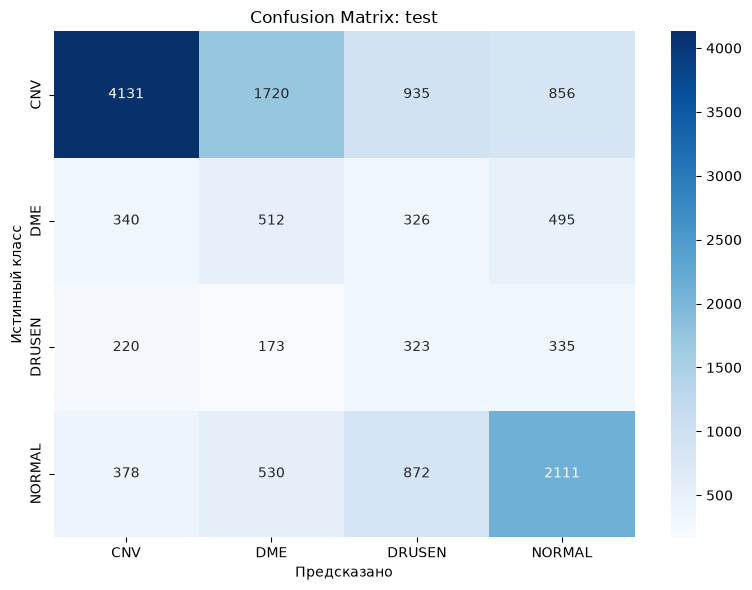

Сохранено: results\cm_test_logreg.png

Метрики сохранены в: results\baseline_logreg_metrics.csv

Сводная таблица:
       model split  accuracy  macro_f1  roc_auc_macro  recall_CNV  recall_DME  recall_DRUSEN  recall_NORMAL
logreg_32x32   val    0.4537    0.4020         0.6835      0.4806      0.2981         0.3158         0.5461
logreg_32x32  test    0.4964    0.4014         0.7142      0.5406      0.3060         0.3073         0.5425


In [9]:
# ========== Оценка ==========
import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, 
    roc_auc_score, classification_report, confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Папка для результатов
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

def save_confusion_matrix(cm, classes, name):
    """
    Сохраняет confusion matrix в CSV и PNG, а так же выводит график и матрицу в консоль.
    cm — матрица
    classes — список классов
    name — имя сплита (val/test)
    """

    cm_df = pd.DataFrame(cm, index=classes, columns=classes)
    save_path = RESULTS_DIR / f"cm_{name}_logreg.csv"
    cm_df.to_csv(save_path)
    print(cm_df)
    print(f"Сохранено: {save_path}")

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm, 
        annot=True,          # показывать числа
        fmt="d",             # целые числа
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes
    )
    plt.xlabel("Предсказано")
    plt.ylabel("Истинный класс")
    plt.title(f"Confusion Matrix: {name}")
    plt.tight_layout()
    
    save_path = RESULTS_DIR / f"cm_{name}_logreg.png"
    plt.savefig(save_path, dpi=150)
    plt.show()
    print(f"Сохранено: {save_path}")

def compute_and_print_metrics(name, y_true, y_pred, y_proba, classes):
    """
    Вычисляет и выводит метрики для заданного сплита.
    name — имя сплита (val/test)
    y_true — истинные значения
    y_pred — предсказанные значения
    y_proba — предсказанные вероятности (для ROC-AUC)
    classes — список классов
    """

    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    auc = roc_auc_score(y_true, y_proba, multi_class="ovr", average="macro")
    recalls = recall_score(y_true, y_pred, average=None)
    
    print(f"\n{'='*40}")
    print(f"  {name.upper()}")
    print(f"{'='*40}")
    print(f"Accuracy:     {acc:.4f}")
    print(f"Macro-F1:     {macro_f1:.4f}")
    print(f"ROC-AUC:      {auc:.4f}")
    print("\nRecall по классам:")
    for cls, rec in zip(classes, recalls):
        print(f"  {cls:8}: {rec:.4f}")
    
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=classes))
    
    print("Confusion Matrix:")
    cm = confusion_matrix(y_true, y_pred)
    save_confusion_matrix(cm, classes, name)
    
    # Собираем словарь для таблицы
    metrics = {
        "split": name,
        "accuracy": acc,
        "macro_f1": macro_f1,
        "roc_auc_macro": auc,
    }

    for cls, rec in zip(classes, recalls):
        metrics[f"recall_{cls}"] = rec
    
    return metrics

all_results = []

for name, X, y in [("val", X_val, y_val), ("test", X_test, y_test)]:
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)
    
    m = compute_and_print_metrics(name, y, y_pred, y_proba, le.classes_)
    m["model"] = "logreg_32x32"
    all_results.append(m)

# Сохраняем в CSV
results_df = pd.DataFrame(all_results)

# Упорядочиваем колонки
cols = ["model", "split", "accuracy", "macro_f1", "roc_auc_macro"] + \
       [c for c in results_df.columns if c.startswith("recall_")]
results_df = results_df[cols]

save_path = RESULTS_DIR / "baseline_logreg_metrics.csv"
results_df.to_csv(save_path, index=False)

print(f"\nМетрики сохранены в: {save_path}")
print("\nСводная таблица:")
print(results_df.round(4).to_string(index=False))

Запускаю t-SNE...


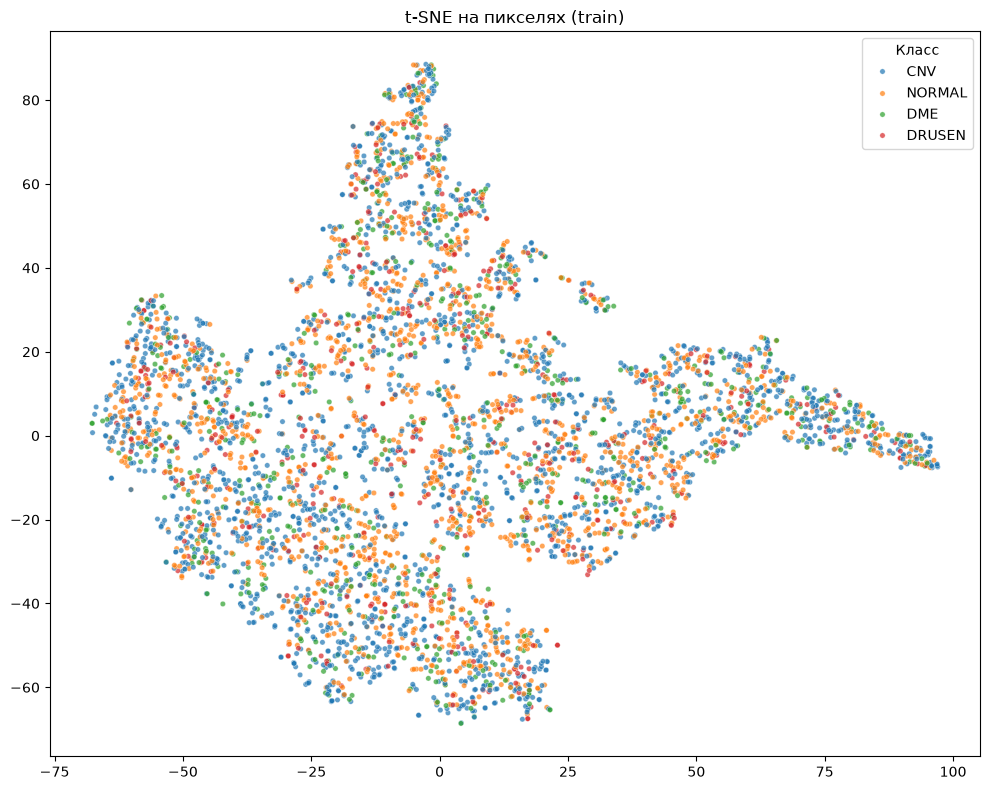

In [10]:
# ========== t-SNE ==========

from sklearn.manifold import TSNE

N = 5000
idx = np.random.choice(len(X_train), size=min(N, len(X_train)), replace=False)


X_sample = X_train[idx]
y_sample = y_train[idx]
labels_sample = le.inverse_transform(y_sample)

print("Запускаю t-SNE...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_jobs=-1)
X_tsne = tsne.fit_transform(X_sample)

# Рисуем
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=X_tsne[:, 0], 
    y=X_tsne[:, 1], 
    hue=labels_sample,
    palette="tab10",
    s=15,
    alpha=0.7
)
plt.title("t-SNE на пикселях (train)")
plt.legend(title="Класс")
plt.tight_layout()
plt.savefig("results/tsne_logreg_pixels.png", dpi=150)
plt.show()

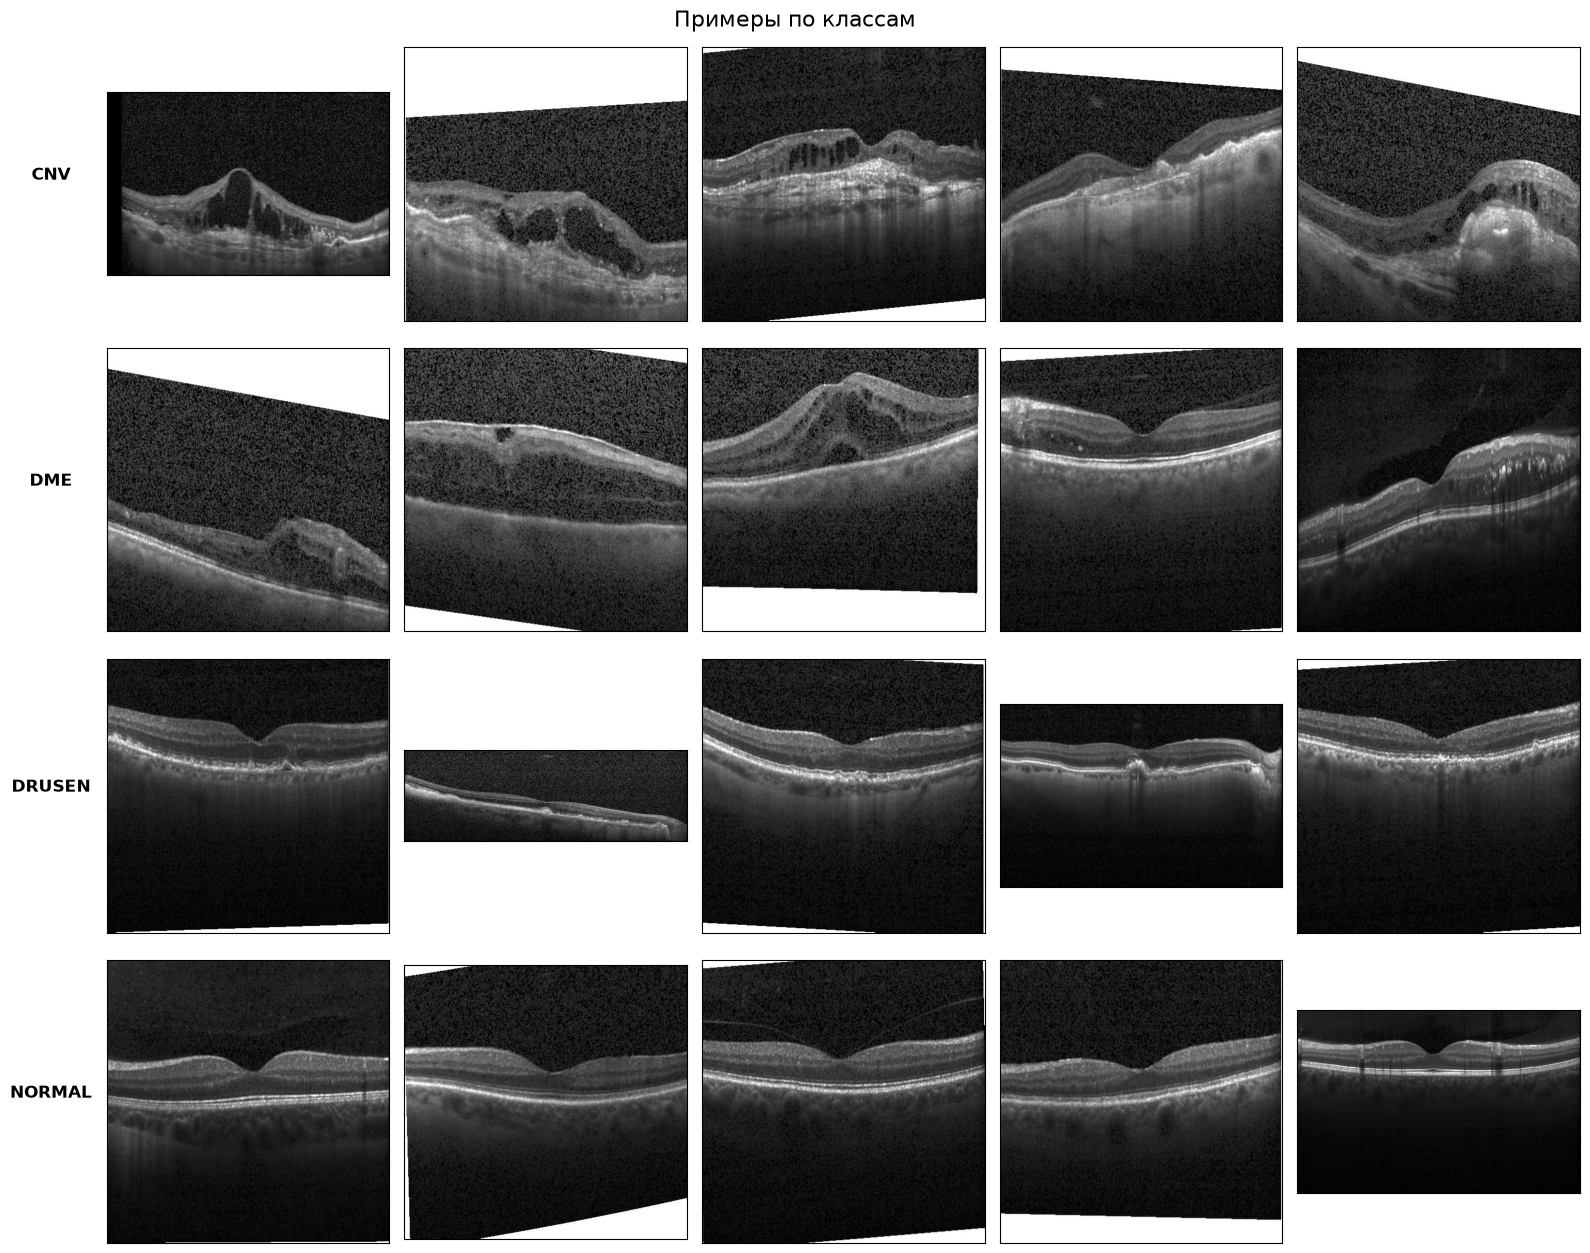

In [11]:
# ========== Примеры картинок по классам ==========

import matplotlib.pyplot as plt
from PIL import Image

def show_class_examples(df, classes, n_per_class=4, title="Примеры по классам"):
    """
    Показывает примеры картинок по разным классам

    df — DataFrame с колонками "path" и "label"
    classes — список классов для отображения
    n_per_class — количество примеров на класс
    title — заголовок графика
    """
    fig, axes = plt.subplots(len(classes), n_per_class, 
                             figsize=(3.2 * n_per_class, 3.2 * len(classes)))
    
    if len(classes) == 1:
        axes = [axes]
    
    for i, cls in enumerate(classes):
        subset = df[df["label"] == cls]
        if len(subset) == 0:
            continue
            
        samples = subset.sample(n=min(n_per_class, len(subset)), random_state=42)
        
        for j, (_, row) in enumerate(samples.iterrows()):
            img = Image.open(row["path"])
            ax = axes[i, j] if len(classes) > 1 else axes[j]
            ax.imshow(img, cmap="gray")
            if j == 0:
                ax.set_ylabel(cls, fontsize=12, fontweight="bold", rotation=0, labelpad=40)
            ax.set_xticks([])
            ax.set_yticks([])
    
    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

# Использование
classes_to_show = ["CNV", "DME", "DRUSEN", "NORMAL"]
show_class_examples(test_df, classes=classes_to_show, n_per_class=5)


CNV → DME: найдено 1720 ошибок


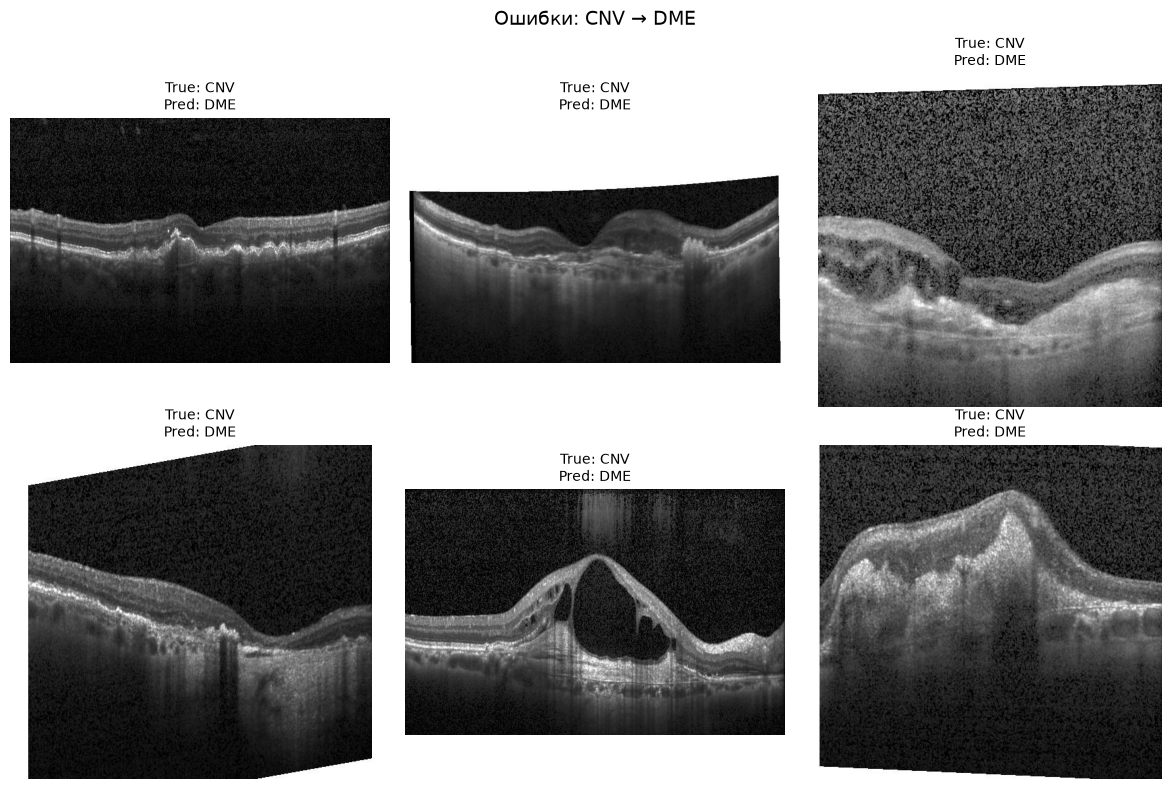


CNV → DRUSEN: найдено 935 ошибок


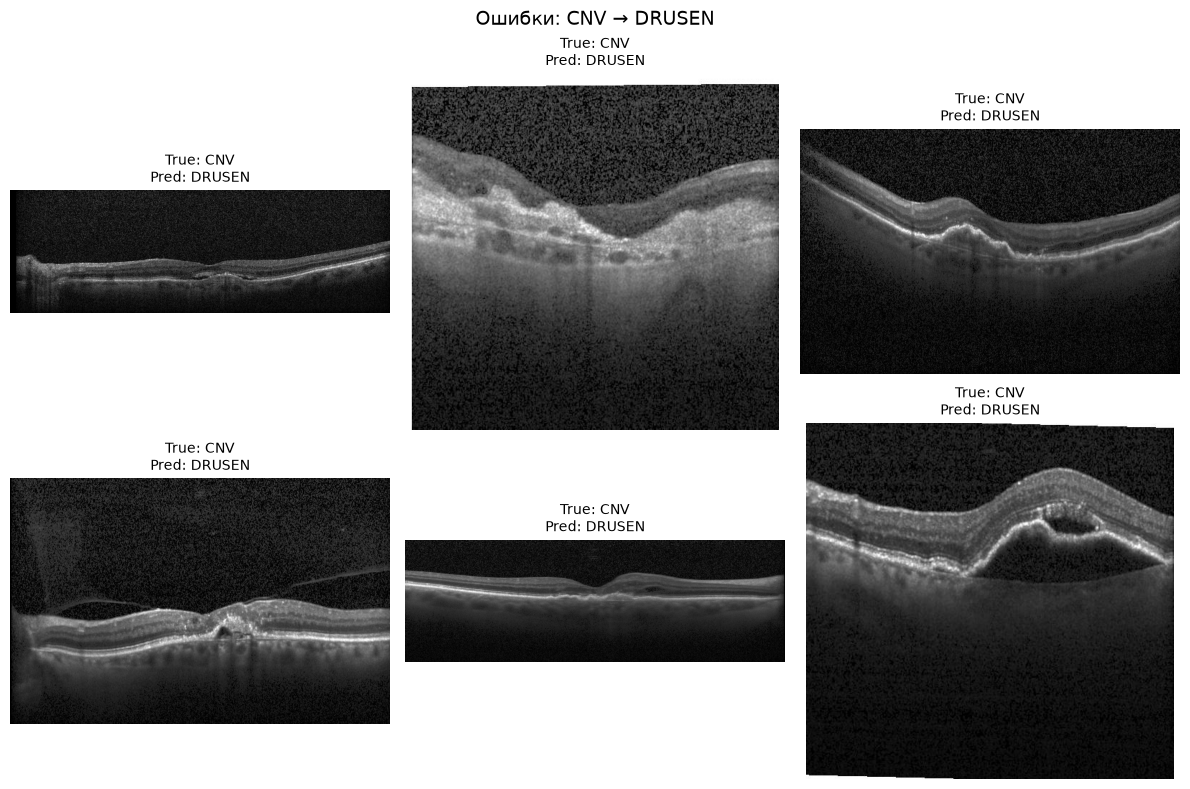


NORMAL → DRUSEN: найдено 872 ошибок


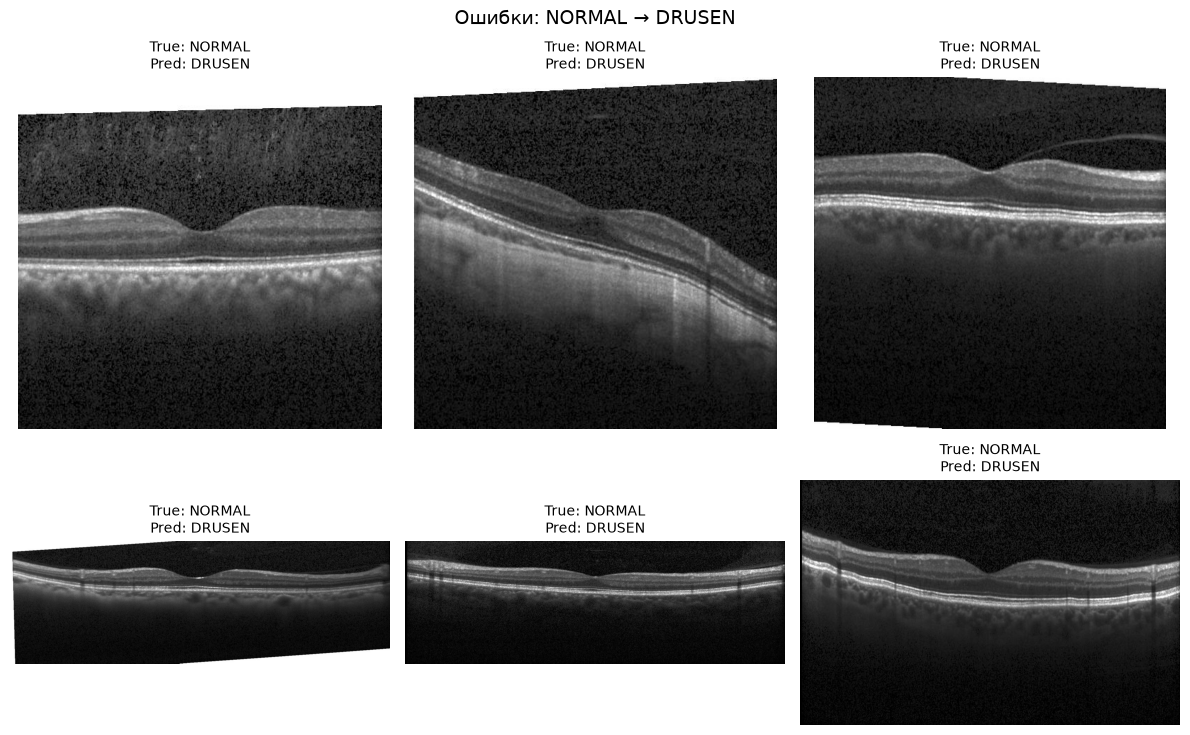


CNV → NORMAL: найдено 856 ошибок


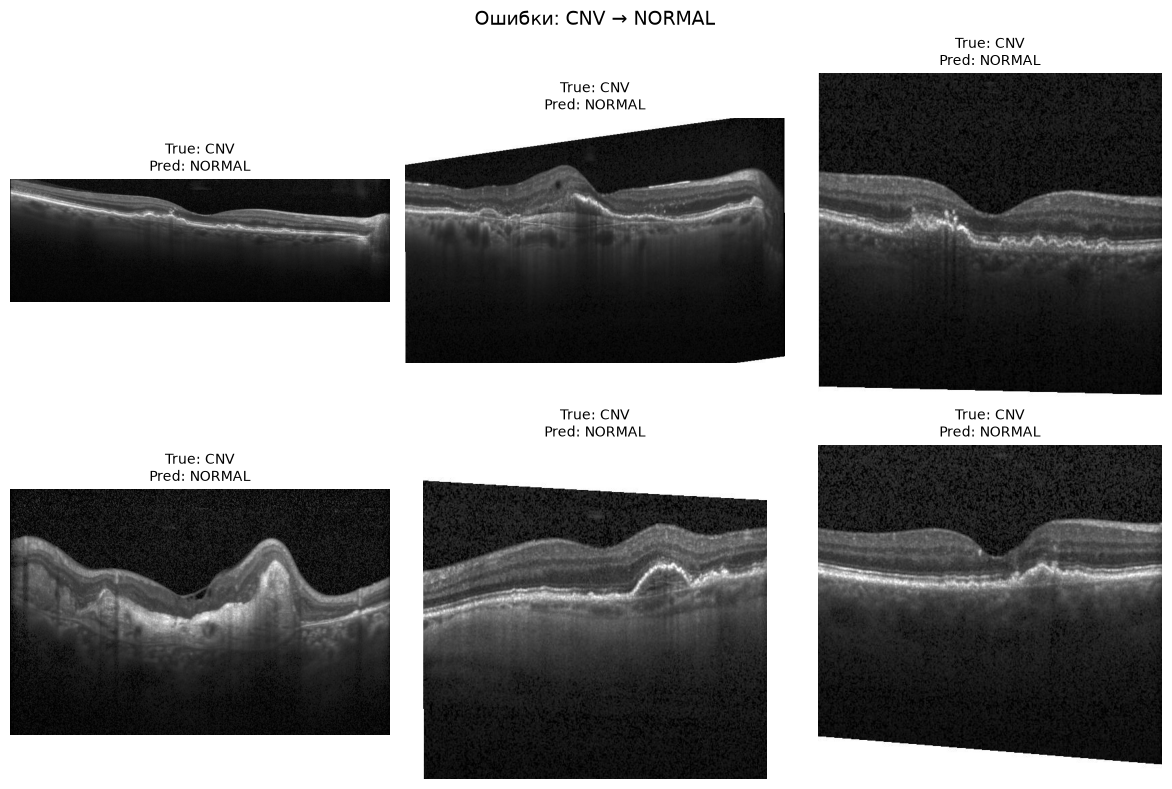

In [12]:
# ========== Примеры ошибок классификации ==========

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Предсказания на тесте
y_pred = model.predict(X_test)
y_true = y_test

# Названия классов
classes = le.classes_

# Пары ошибок
error_pairs = [
    ("CNV", "DME"),
    ("CNV", "DRUSEN"),
    ("NORMAL", "DRUSEN"),
    ("CNV", "NORMAL"),
]

def show_error_examples(true_label, pred_label, n=6):
    """
    Показывает n примеров, где истинный класс = true_label, а модель предсказала pred_label

    true_label — истинный класс (строка)
    pred_label — предсказанный класс (строка)
    n — количество примеров для отображения
    """
    true_idx = le.transform([true_label])[0]
    pred_idx = le.transform([pred_label])[0]
    
    # Находим индексы ошибок
    mask = (y_true == true_idx) & (y_pred == pred_idx)
    error_indices = np.where(mask)[0]
    
    print(f"\n{true_label} → {pred_label}: найдено {len(error_indices)} ошибок")
    
    if len(error_indices) == 0:
        print("Таких ошибок нет")
        return
    
    # Берём несколько случайных
    show_idx = np.random.choice(error_indices, size=min(n, len(error_indices)), replace=False)
    
    # Рисуем
    cols = min(3, len(show_idx))
    rows = (len(show_idx) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 4*rows))
    axes = np.array(axes).reshape(-1)
    
    for i, idx in enumerate(show_idx):
        # Достаём путь к оригинальной картинке
        path = test_df.iloc[idx]["path"]
        img = Image.open(path)
        
        axes[i].imshow(img, cmap="gray")
        axes[i].set_title(f"True: {true_label}\nPred: {pred_label}", fontsize=10)
        axes[i].axis("off")
    
    # Прячем лишние оси
    for j in range(i+1, len(axes)):
        axes[j].axis("off")
    
    plt.suptitle(f"Ошибки: {true_label} → {pred_label}", fontsize=14)
    plt.tight_layout()
    plt.show()

# Показываем примеры для каждой пары
for true_lbl, pred_lbl in error_pairs:
    show_error_examples(true_lbl, pred_lbl, n=6)

Выводы:
1. Логистическая регрессия плохо справляется с задачей, это подтверждают метрики, и t-SNE показывает, что классы сгруппированы сложно, провести простые линии для их разделения не получится.
2. Все классы имеют recall ниже 55%
3. Худшее угадывание классов (истинный класс - предсказанный класс) у CNV - DME, CNV - DRUSEN, NORMAL - DRUSEN и CNV - NORMAL.
4. CNV - DME - очевидная ошибка, паталогии включат в себя просачивание ждикости и крови из новых хрупких сосудов (CNV) и утолщение сетчатки и образование кисты (DME), на картинках их тоже легко перепутать. CNV более опасное заболевание, чем DME, поэтому ошибка в классификации здесь критичная.
5. CNV - DRUSEN опять же, опасная мисклассификация. Понятно, почему - фотки из примера по CNV действительно выглядят, как DRUSEN (бугорки под сетчаткой). Тоже стоит обратить внимание.
6. NORMAL - DRUSEN - False Positive, в медицине лучше перебдеть, поэтому результат норм. Примеры картинок выглядят как NORMAL.
7. CNV - NORMAL - еще одна опасная ошибка, следует обратить внимание.
8. Confusion matrix показывает классы заболеваний от самой опсаной до normal, следует обратить внимание на это при обучении более продвинутых моделей.